<a href="https://colab.research.google.com/github/abaker2-commits/change/blob/main/anagram.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from itertools import permutations

def brute_force_anagram(s1, s2):
    # Remove spaces and lowercase for phrases like
    # "dormitory" and "dirty room" can be compared equally
    s1 = s1.replace(" ", "").lower()
    s2 = s2.replace(" ", "").lower()

    # Different lengths can never be anagrams
    if len(s1) != len(s2):
        return False

    # Generate every possible ordering of s1
    for candidate in permutations(s1):
        if "".join(candidate) == s2:
            return True

    # No arrangement matched
    return False

# Tests
print(brute_force_anagram("cinema", "iceman"))          # True
print(brute_force_anagram("alert", "later"))        # True
print(brute_force_anagram("dormitory", "dirty room")) # True
print(brute_force_anagram("credit", "direct"))       # True
print(brute_force_anagram("stressed", "messed"))       # False

True
True
True
True
False


In [ ]:
def sort_and_compare(s1, s2):
    s1 = s1.replace(" ", "").lower()
    s2 = s2.replace(" ", "").lower()
    return sorted(s1) == sorted(s2)

print(sort_and_compare("python", "typhon"))          # True
print(sort_and_compare("dormitory", "dirty room"))    # True

True
True


### Complexity Analysis

1. **Brute Force (Permutations) Approach**:
   - **Time Complexity**: $O(N!)$ where $N$ is the length of the string. Generating all permutations takes factorial time, which grows extremely rapidly. For a string of length 10, there are over 3.6 million permutations. For length 11, it is nearly 40 million, making this approach completely impractical for longer strings.
   - **Space Complexity**: $O(N)$ or $O(N!)$ depending on implementation (to store the permutations or the call stack).

2. **Sorting Approach**:
   - **Time Complexity**: $O(N \log N)$ because sorting a string of length $N$ takes $O(N \log N)$ time using Timsort (Python's built-in sorting algorithm), followed by a linear comparison $O(N)$. This is highly efficient and easily handles strings with thousands of characters.
   - **Space Complexity**: $O(N)$ to store the sorted lists or strings.

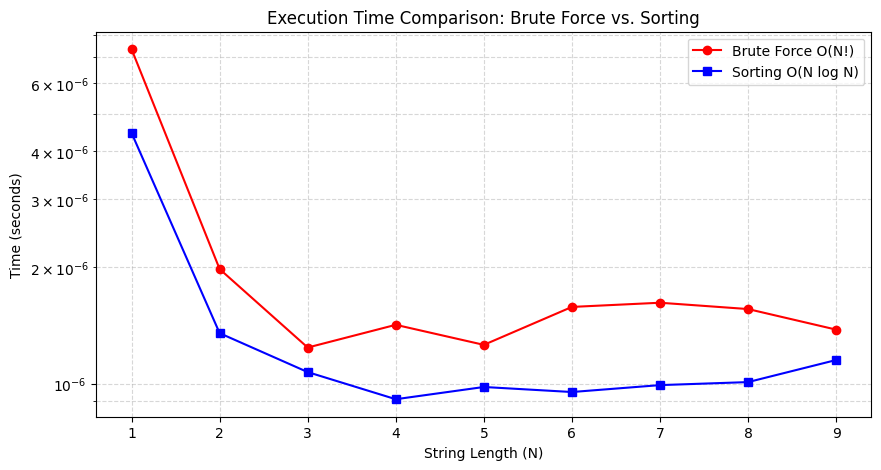

In [ ]:
import time
import matplotlib.pyplot as plt

# The benchmark the two approaches using strings of increasing lengths
lengths = list(range(1, 10))  # Keep lengths small because O(N!) grows extremely fast
brute_times = []
sort_times = []

for n in lengths:
    s1 = "a" * n
    s2 = "a" * n

    # Benchmark Brute Force
    start = time.perf_counter()
    brute_force_anagram(s1, s2)
    brute_times.append(time.perf_counter() - start)

    # Benchmark Sorting
    start = time.perf_counter()
    sort_and_compare(s1, s2)
    sort_times.append(time.perf_counter() - start)

# Plot the results
plt.figure(figsize=(10, 5))
plt.plot(lengths, brute_times, label='Brute Force O(N!)', marker='o', color='red')
plt.plot(lengths, sort_times, label='Sorting O(N log N)', marker='s', color='blue')
plt.title('Execution Time Comparison: Brute Force vs. Sorting')
plt.xlabel('String Length (N)')
plt.ylabel('Time (seconds)')
plt.yscale('log')  # Log scale to handle the massive difference in scale
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()